# Portfolio VaR and PCA Analysis

## Background

I have always been interested in seeing how we can predict and quantify how risky are investments may be. Using methods learned, we can actually see!


All the calculations live in `risk_tool.py`. This notebook only calls them and shows the results. `import risk_tool as rt` loads the file, so each function is called as `rt.function_name(...)`. 

We select `SPY`, `EFA`, `IEF`, and `GLD`, as our tickers for our demo, as it has a large spread of variability. The chosen weights are scaled naively, but simulates a riskier portfolio.

In [18]:
import pandas as pd
import risk_tool as rt
import matplotlib.pyplot as plt

In [2]:
tickers = ["SPY", "EFA", "IEF", "GLD"]
weights = [0.50, 0.25, 0.15, 0.10]
w = pd.Series(weights, index=tickers)

#### Under the hood: the weight vector
The four weights form a vector

$$
\mathbf{w} =
\begin{bmatrix} w_{\text{SPY}} \\ w_{\text{EFA}} \\ w_{\text{IEF}} \\ w_{\text{GLD}} \end{bmatrix}
=
\begin{bmatrix} 0.50 \\ 0.25 \\ 0.15 \\ 0.10 \end{bmatrix},
\qquad \sum_i w_i = 1, \quad w_i \ge 0
$$

Equities (SPY + EFA) are 75% of capital, bonds (IEF) 15% and gold (GLD) 10%.

Storing the weights as a pandas Series with the tickers as its index means every later calculation matches weights to assets **by name**, not by position. This matters because yfinance returns columns in alphabetical order (EFA, GLD, IEF, SPY), not the order typed here.

We use `rt.check_inputs(tickers, weights)` to check that there is one weight per ticker, that the weights add up to 1, and that none are negative.

In [3]:
rt.check_inputs(tickers, weights)

`check_inputs` stops with an error if, (1) the number of weights differs from the number of tickers, (2) the weights don't sum to 1 (within $10^{-6}$, to allow for rounding), or (3) any weight is negative.

In [4]:
prices = rt.load_prices(tickers) # downloads the prices from yfinance
prices

[*********************100%***********************]  4 of 4 completed


Ticker,EFA,GLD,IEF,SPY
Date,,,,
2012-01-03,32.864265,155.919998,76.110870,98.811638
2012-01-04,32.670498,156.710007,75.871437,98.966629
2012-01-05,32.186047,157.779999,75.885933,99.230125
2012-01-06,31.746824,157.199997,76.183495,98.974388
2012-01-09,31.869553,156.500000,76.197975,99.214630
...,...,...,...,...
2026-09-22,106.500000,400.070007,91.160004,773.380005
2026-09-23,104.800003,392.880005,90.190002,767.809998
2026-09-24,104.500000,391.690002,89.690002,767.179993


`yf.download(...)["Close"]` returns one row per trading day and one column per ticker: 3,704 trading days from January 2012 to September 2026.

These are **adjusted** closing prices: past prices are scaled down for dividends and splits, so the change from one day to the next reflects the total return an investor earned, not just the price move. Without the adjustment, every dividend payment would look like a small loss.

In order to backtest the VaR, we need a large amount of data: at least 1,250 trading days.

In [5]:
rt.check_history(prices)

OK: contians 3,705 days (need 1,250).


3705

#### Is there enough data?
The backtest will estimate the VaR each day from the previous 500 days, which allows the first 500 days train the model. At least 750 more days are needed for the Kupiec test to properly judge it. At a 5% breach rate that's about 37 expected breaches, which means that the check requires 1250 days

$$
\text{usable days} \ge 500 + 750 = 1{,}250
$$

"Usable days" are the dates on which **every** ticker has a price (`len(prices.dropna())`), because a single late-starting ticker would shorten the whole dataset. All four ETFs trade back to 2012, so all 3,704 days are usable.

In [6]:
returns = rt.compute_returns(prices)
returns.tail()


Ticker,EFA,GLD,IEF,SPY
Date,,,,
2026-09-22,0.003486,0.004242,0.000110,-0.000155
2026-09-23,-0.015962,-0.017972,-0.010641,-0.007202
2026-09-24,-0.002863,-0.003029,-0.005544,-0.000821
2026-09-25,0.010144,0.004391,0.003456,0.005435
2026-09-28,-0.004926,-0.039399,-0.005222,-0.007441


#### Daily returns
For each asset $i$ and day $t$, the simple daily return is

$$
r_{t,i} = \frac{P_{t,i} - P_{t-1,i}}{P_{t-1,i}} = \frac{P_{t,i}}{P_{t-1,i}} - 1
$$

which is what `.pct_change()` computes.

Note: The first day has no previous price, so its return is empty with `.dropna()` removing it, thus leaving 3,703 days.

Risk models use returns rather than prices because returns are comparable across assets where as prices are not really. For example, a \$5 move means something very different for a \$90 bond ETF than for a \$770 SPY share, while a 1% move means the same for both.

The result is a $T \times N$ matrix $R$, with $T = 3{,}703$ days and $N = 4$ assets, for our example. 

In [7]:
risk_share = rt.risk_shares(returns, w)
risk_share


,weight,risk_share
SPY,0.50,0.648924
EFA,0.25,0.317104
IEF,0.15,-0.002757
GLD,0.10,0.036729


#### Risk contributions

We begin the process of finding our risk contributers by preparing for PCA in three steps. The function `risk_shares()` applies the following:


**1: The Covariance Matrix.** `returns.cov()` estimates the sample covariance of each pair of assets, given by

$$
\hat\sigma_{ij} = \frac{1}{T-1}\sum_{t=1}^{T}(r_{t,i}-\bar r_i)(r_{t,j}-\bar r_j),
$$

Where $t$ is the particular day, $T$ is the total days, $i$ and $j$ are the assets being compared, $r_{t,i}$ being asset $i$'s return on day $t$, $\bar r_i$ being asset $i$'s average daily return over all $T$ days.

Covariance gives us an understanding of, **if one stock returns above average, does the other one being compared also return above average?** The covariance is then calculated for each pair in the vectors, resulting in an arrangement of a $4 \times 4$ matrix $\Sigma$ (for this example). The diagonal holds each asset's variance, since $\operatorname{Cov}(X, X) = \operatorname{Var}(X)$. Meaning that the off-diagonal entries show how pairs of assets move together.


**2. Portfolio variance.** The portfolio's daily return is a weighted sum of the asset returns, $r_{p,t} = \mathbf{w}^\top \mathbf{r}_t$. By the variance of a linear combination,

$$
\sigma_p^2 = \operatorname{Var}(r_p)  = \sum_i \sum_j w_i\, w_j\, \sigma_{ij}
$$

which gives us $$\operatorname{Var}(r_p) = \mathbf{w}^\top \Sigma\, \mathbf{w}$$





**3. Split the variance by asset.** 
To calculate risk share, we have to differentiate portfolio variance with respect to the weights, giving us $$\partial \sigma_p^2 / \partial \mathbf{w} = 2\Sigma\mathbf{w}$$ this is the same derivative used to derive PCA, but we have divide it with respect with the weight instead of the eigenvectors. Since our weights are not eigenvectors, we do not equate to zero and solve. 

Each asset's share of portfolio variance follows Qian (2006, eq. 2), written in matrix form:

$$
\text{RS}_i = \frac{w_i\,(\Sigma\mathbf{w})_i}{\mathbf{w}^\top \Sigma\, \mathbf{w}}, \qquad \sum_i \text{RS}_i = 1
$$

where $(\Sigma\mathbf{w})_i = \operatorname{Cov}(r_i, r_p)$ measures how much asset $i$ moves with the whole portfolio. A negative covariance in this case would indicate being the asset acts as a hedge.

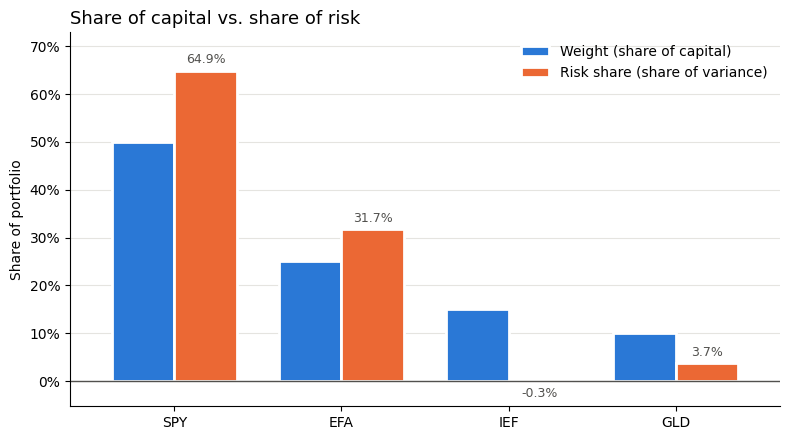

In [8]:
rt.plot_risk_shares(risk_share)

From our graph, we see that the blue bars show each asset's share of capital, whereas the orange bars show its share of risk. Where orange is taller than blue (e.g., SPY, EFA), it means that the asset contributes more risk than its weight suggests. Where it's shorter (e.g., IEF, GLD), it contributes less risk. Interestingly, IEF's orange bar sits at or below zero.

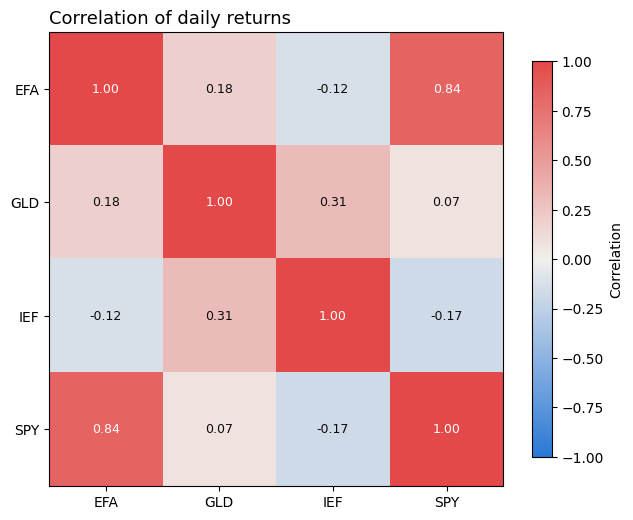

In [9]:
rt.plot_correlations(returns)

#### Correlation Matrix Graph

Each cell/block is the correlation between two assets' daily returns. In detail, the formula gives it as their covariance scaled by both volatilities, where 

$$
\operatorname{Corr}(i,j) = \rho_{ij} = \frac{\sigma_{ij}}{\sigma_i\,\sigma_j}, \qquad -1 \le \rho_{ij} \le 1
$$

The colour scale is fixed from −1 (blue, moves opposite) through 0 (gray, unrelated) to +1 (red, moves together). Note that the this correlation matrix is symmetric.

**Brief Analysis**

from the period for our selected data, which is ~3000 days since the latest run:

- **SPY and EFA: 0.84.** US and international stocks move together most of the time, so holding both adds little diversification. This is why their combined risk share (97%) is so much higher than their weight (75%).
- **IEF with stocks: −0.12 to −0.17.** Over the full period, bonds moved slightly against stocks, which is why IEF's risk share is slightly negative. This relationship has reversed since (around) 2021. Please see the rolling correlation graph below!. 
- **GLD and IEF: 0.31.** Gold and bonds share some behaviour, but not a lot. Both are assets investors buy in uncertain times. 
- **GLD with stocks: 0.07 to 0.18.** Gold is close to independent of equities, so its risk share (~3.7%) is well below its weight (10%).

#### Aside: Inflation

I wanted to make some diagrams that illustrates the correlation between SPY and bonds, since bonds are such a hot topic right now.

<Axes: title={'center': 'SPY–IEF 1-year rolling correlation'}, xlabel='Date'>

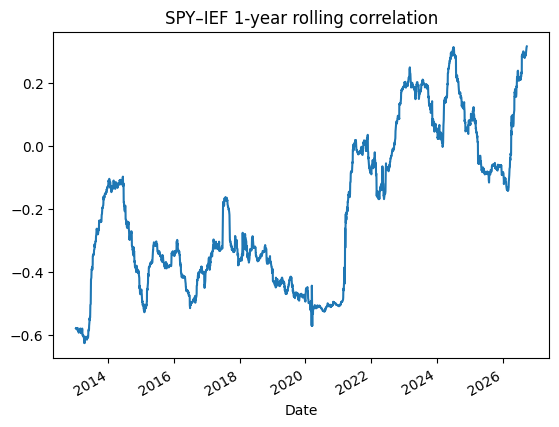

In [11]:
returns["SPY"].rolling(252).corr(returns["IEF"]).plot(title="SPY–IEF 1-year rolling correlation")

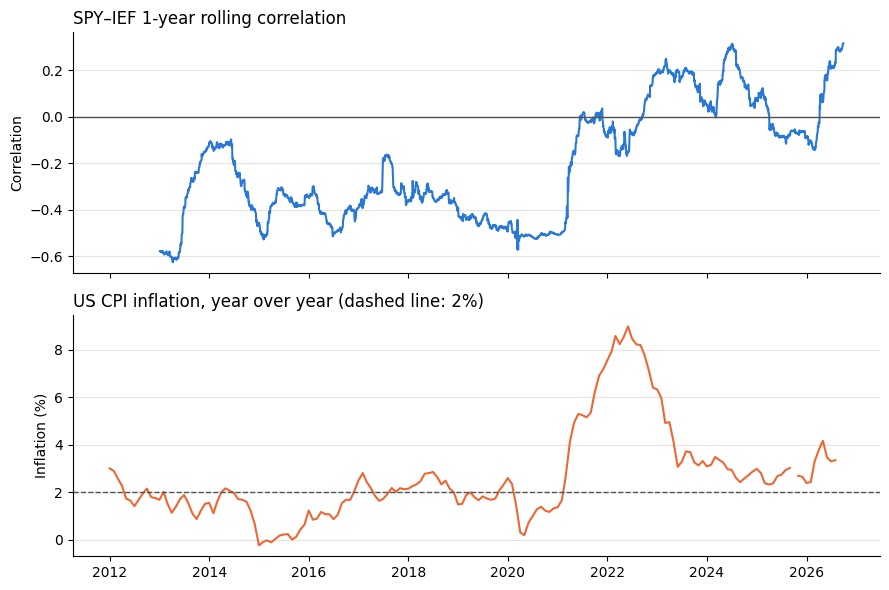

In [19]:
#US Consumer Price Index, monthly, from FRED
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL"
cpi = pd.read_csv(url, index_col=0, parse_dates=True).iloc[:, 0]
inflation = cpi.pct_change(12, fill_method=None) * 100    
inflation = inflation.loc["2012":]

roll_corr = returns["SPY"].rolling(252).corr(returns["IEF"])

#stacked panels sharing the same dates
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 6))

ax1.plot(roll_corr, color="#2a78d6")
ax1.axhline(0, color="#52514e", linewidth=1)
ax1.set_ylabel("Correlation")
ax1.set_title("SPY–IEF 1-year rolling correlation", loc="left")

ax2.plot(inflation, color="#eb6834")
ax2.axhline(2, color="#52514e", linewidth=1, linestyle="--")
ax2.set_ylabel("Inflation (%)")
ax2.set_title("US CPI inflation, year over year (dashed line: 2%)", loc="left")

for ax in (ax1, ax2):
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

From what we can see during the massive increase in inflation during the pandemic era, had an effect on the bond and stock market. Essentially, the bond hedge diappears as intrest rates rose. We can observe that the correlation increased as the inflation increased. 

Aside - Finished

### Principal Component Analysis

We want to ask the question on how many independent sources of risk does the portfolio really have? PCA allows us to find the answer by calculating the combinations of assets that capture the most variation in returns. 

The solution to solving PCA is to find that the principal components are the eigenvectors $\mathbf{v}_k$ of $C$, and each eigenvalue $\lambda_k$ is the variance of that component:

$$
C\,\mathbf{v}_k = \lambda_k\,\mathbf{v}_k, \qquad \text{share explained}_k = \frac{\lambda_k}{\sum_j \lambda_j}
$$



In [37]:
explained, loadings = rt.pca_concentration(returns)
print(loadings.round(2))

Ticker
EFA    0.69
GLD    0.14
IEF   -0.17
SPY    0.69
dtype: float64


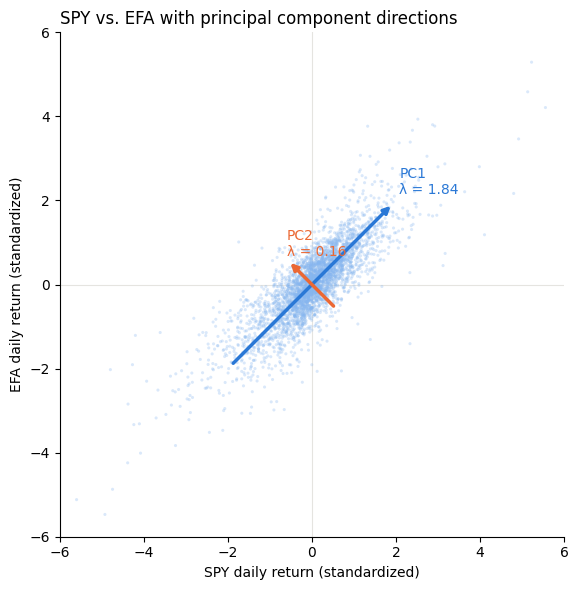

In [28]:
import numpy as np
import matplotlib.pyplot as plt

pair = ["SPY", "EFA"]
z = (returns[pair] - returns[pair].mean()) / returns[pair].std()   # standardize

eigvals, eigvecs = np.linalg.eigh(z.corr())         # eigen-decomposition of the 2x2 correlation matrix
eigvals, eigvecs = eigvals[::-1], eigvecs[:, ::-1]  # largest first
for k in range(2):                                  # flip signs so arrows point up/right
    if eigvecs[:, k].sum() < 0:
        eigvecs[:, k] = -eigvecs[:, k]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(z["SPY"], z["EFA"], s=5, alpha=0.3, color="#86b6ef", edgecolor="none")

colors = ["#2a78d6", "#eb6834"]
for k in range(2):
    v = eigvecs[:, k]
    length = 2 * np.sqrt(eigvals[k])                # longer arrow = more spread in that direction
    ax.annotate("", xy=length * v, xytext=-length * v,
                arrowprops=dict(arrowstyle="-|>", color=colors[k], lw=2.5))
    ax.text(*(length * v * 1.08), f"PC{k+1}\nλ = {eigvals[k]:.2f}",
            color=colors[k], fontsize=10, ha="left", va="bottom")

ax.axhline(0, color="#e5e4e0", lw=0.8, zorder=0)
ax.axvline(0, color="#e5e4e0", lw=0.8, zorder=0)
ax.set_aspect("equal")
ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)
ax.set_xlabel("SPY daily return (standardized)")
ax.set_ylabel("EFA daily return (standardized)")
ax.set_title("SPY vs. EFA with principal component directions", loc="left", fontsize=12)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()